# 4 · Unit roots, cointegration and a VECM, done on the right objects
Cointegration asks whether a linear combination of **non-stationary price levels** is stationary, i.e. whether the series share a long-run equilibrium. A common mistake is to run the test on *returns*. Returns are already stationary, so the test rejects "no cointegration" almost every time and the "finding" is meaningless. This notebook:

1. shows the mistake with a simulation of independent random walks;
2. tests gold, the CAC 40 ETF, Bitcoin and the S&P 500 properly on log prices;
3. finds a genuine cointegrating relation in the Treasury curve and models it with a VECM.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)
from fineco import data
from fineco import cointegration as co

In [2]:
demo = co.spurious_returns_demo(n=1000, n_sims=300)
print(f"Independent random walks, Engle-Granger at 5%:\n  tested on levels : rejects {demo['reject_rate_levels']:.0%} (correct size is about 5%)\n  tested on returns: rejects {demo['reject_rate_returns']:.0%} (spurious)")

Independent random walks, Engle-Granger at 5%:
  tested on levels : rejects 6% (correct size is about 5%)
  tested on returns: rejects 100% (spurious)


In [3]:
lp = np.log(data.load_prices())
co.unit_root_table(lp)

ADF_p KPSS_p    verdict
bitcoin   level  0.831   0.01  unit root
          diff     0.0    0.1       I(0)
cac40_etf level  0.712   0.01  unit root
          diff     0.0    0.1       I(0)
gold_etf  level  0.956   0.01  unit root
          diff     0.0    0.1       I(0)
sp500     level  0.919   0.01  unit root
          diff     0.0    0.1       I(0)

In [4]:
eg = co.engle_granger_matrix(lp)
eg

,bitcoin,cac40_etf,gold_etf,sp500
bitcoin,NaN,0.177,0.653,0.226
cac40_etf,0.136,NaN,0.357,0.456
gold_etf,0.729,0.484,NaN,0.282
sp500,0.296,0.620,0.251,NaN


In [5]:
co.johansen_table(lp, k_ar_diff=1)

,H0: rank <=,trace,trace_crit_5%,max_eig,max_eig_crit_5%,reject_trace_5%
0,0,36.397,47.855,22.176,27.586,False
1,1,14.221,29.796,10.100,21.131,False
2,2,4.121,15.494,4.106,14.264,False
3,3,0.015,3.841,0.015,3.841,False


share of 2-year windows with EG p < 0.05 (gold vs S&P 500): 2%


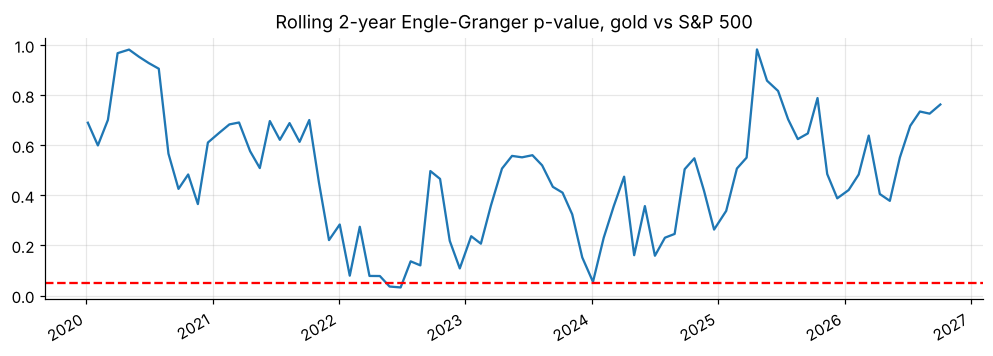

In [6]:
roll = co.rolling_eg_pvalue(lp["gold_etf"], lp["sp500"], window=500, step=20)
print(f"share of 2-year windows with EG p < 0.05 (gold vs S&P 500): {(roll < .05).mean():.0%}")
ax = roll.plot(title="Rolling 2-year Engle-Granger p-value, gold vs S&P 500", figsize=(11, 3.5))
ax.axhline(.05, c="r", ls="--"); plt.savefig(FIG / "04_rolling_eg.png", bbox_inches="tight"); plt.show()

## A relationship that does hold: the Treasury curve
Yields at different maturities are each close to I(1) but are tied together by arbitrage and expectations, so a stationary combination should exist.

In [7]:
Y = data.load_yields()[[1, 5, 10]].rename(columns=lambda c: f"y{c:g}")
display(co.unit_root_table(Y))
co.johansen_table(Y, k_ar_diff=1)

ADF_p KPSS_p    verdict
y1  level  0.831   0.01  unit root
    diff     0.0  0.059       I(0)
y5  level  0.901   0.01  unit root
    diff     0.0    0.1       I(0)
y10 level   0.91   0.01  unit root
    diff     0.0    0.1       I(0)

,H0: rank <=,trace,trace_crit_5%,max_eig,max_eig_crit_5%,reject_trace_5%
0,0,47.611,29.796,42.758,21.131,True
1,1,4.853,15.494,4.288,14.264,False
2,2,0.565,3.841,0.565,3.841,False


lag (BIC) = 1, cointegration rank = 1
normalised cointegrating vector: {'y1': 1.0, 'y5': -3.533, 'y10': 2.455}
adjustment speeds alpha: {'y1': -0.0084, 'y5': -0.0026, 'y10': -0.0031}
ADF p-value of the error-correction term: 0.0946
half-life of deviations: 84 trading days


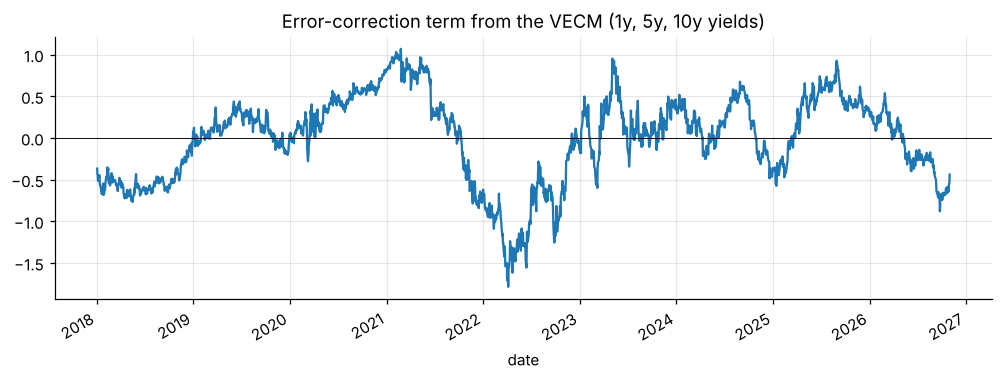

In [8]:
vecm, lag, rank = co.fit_vecm(Y)
beta = vecm.beta[:, 0] / vecm.beta[0, 0]
print(f"lag (BIC) = {lag}, cointegration rank = {rank}")
print("normalised cointegrating vector:", dict(zip(Y.columns, beta.round(3).tolist())))
print("adjustment speeds alpha:", dict(zip(Y.columns, vecm.alpha[:, 0].round(4).tolist())))
ect = pd.Series(Y.values @ vecm.beta[:, 0], index=Y.index)
ect -= ect.mean()
from statsmodels.tsa.stattools import adfuller
print(f"ADF p-value of the error-correction term: {adfuller(ect)[1]:.4f}")
hl = np.log(2) / -np.log(1 + (np.polyfit(ect.shift(1).dropna(), ect.diff().dropna(), 1)[0]))
print(f"half-life of deviations: {hl:.0f} trading days")
ax = ect.plot(title="Error-correction term from the VECM (1y, 5y, 10y yields)", figsize=(11, 3.5))
ax.axhline(0, c="k", lw=.6); plt.savefig(FIG / "04_ect.png", bbox_inches="tight"); plt.show()

## Findings
* The simulation shows the classic error. On independent random walks, Engle-Granger rejects 6% of the time on levels (close to the nominal 5%) but **100%** of the time on returns. A "cointegration" result computed on returns is meaningless.
* All four asset log prices are I(1) (ADF does not reject a unit root; KPSS rejects stationarity). Their first differences are I(0).
* **No pair or group of the four assets is cointegrated.** Every pairwise Engle-Granger p-value is above 0.13, the Johansen trace test does not reject rank 0, and only 2% of rolling 2-year windows for gold vs S&P 500 dip below 5%. There is no long-run equilibrium to trade or hedge on.
* **The Treasury curve is cointegrated.** For 1y, 5y and 10y yields, Johansen strongly rejects rank 0 (trace 47.6 vs 29.8 critical) and does not reject rank 1. The cointegrating vector 1·y1 − 3.53·y5 + 2.46·y10 is a curvature-like combination. Deviations decay slowly (half-life about 84 trading days), and a plain ADF on the estimated term gives p = 0.09. So the relation is real but weak at daily frequency, and the slow mean reversion is a warning against treating it as a short-horizon trade.